# The Mathematics Behind Route Optimization
## Finding Efficient Delivery Routes with Python

### 1. Introduction

Route optimization is the process of finding an efficient route between multiple locations.

In this project, we will explore how mathematics and Python can help find a short delivery route.

We will consider a simple delivery scenario with one warehouse and five delivery locations.

The goal is to visit every delivery location exactly once, return to the warehouse, and minimize the total travel distance.

We will compare three algorithms:
- Random Route
- Nearest Neighbor
- Brute Force

### 2. Mathematical Problem Definition

This project considers a delivery route optimization problem involving one warehouse and five delivery locations.

A courier must start at the warehouse, visit each delivery location exactly once, and return to the warehouse.

The objective is to find the route with the minimum total travel distance.

The problem is based on the following assumptions:

- The warehouse is the starting and ending point.
- Each delivery location must be visited exactly once.
- All locations are represented by points in a two-dimensional coordinate system.
- Distances between locations are measured using Euclidean distance (straight-line distance).
- Real road networks, traffic conditions, and travel times are not considered.

The mathematical goal is to compare valid routes and identify the one with the shortest total distance.


#### Simplified Symmetric Travelling Salesperson Problem (TSP)

This project models a simplified symmetric Travelling Salesperson Problem (TSP), a classical mathematical optimization problem with practical applications in delivery route planning and logistics.

The problem is symmetric because the Euclidean distance between two locations is the same in both directions:

$$
d(A,B) = d(B,A)
$$

Euclidean distances represent straight-line distances rather than actual driving distances. This simplified model allows us to focus on mathematical optimization without considering the complexity of real road networks.

To explore different approaches to this problem, three algorithms will be compared:

- **Random Route:** Generates a random valid route as a baseline for comparison.
- **Nearest Neighbor:** Uses a heuristic approach by repeatedly selecting the nearest unvisited delivery location.
- **Brute Force:** Evaluates all possible visit sequences to find a globally optimal route.



### 3. Coordinates and Vectors

In this project, the warehouse and delivery locations are represented as points in a two-dimensional coordinate system.

Each point is defined by two coordinates:

- **x** — the horizontal position.
- **y** — the vertical position.

A point can be represented as:

$$
P = (x, y)
$$

For example, consider two points:

$$
A = (1, 2), \quad B = (4, 6)
$$

A vector describes the displacement from one point to another.

The vector from point A to point B is calculated by subtracting their coordinates:

$$
\overrightarrow{AB} = (x_B - x_A,\ y_B - y_A)
$$

For our example:

$$
\overrightarrow{AB} = (4 - 1,\ 6 - 2) = (3, 4)
$$

This means that moving from point A to point B requires a displacement of 3 units horizontally and 4 units vertically.

Vectors help us describe the movement between the warehouse and delivery locations.


#### Relationship Between Vectors and Euclidean Distance

The magnitude (length) of a displacement vector is calculated using the Pythagorean theorem:

$$
|\overrightarrow{AB}| = \sqrt{(x_B-x_A)^2 + (y_B-y_A)^2}
$$

The Euclidean distance between two points equals the magnitude of the displacement vector connecting them:

$$
d(A,B) = |\overrightarrow{AB}|
$$

For the previous example, where the displacement vector is $(3,4)$:

$$
d(A,B) = \sqrt{3^2 + 4^2} = \sqrt{25} = 5
$$

This relationship connects vector geometry with the Euclidean distance calculations used to evaluate delivery routes.




### 4. Euclidean Distance

Euclidean distance is the straight-line distance between two points in a two-dimensional coordinate system.

It is calculated using the Pythagorean theorem.

For two points:

$$
A = (x_A, y_A), \quad B = (x_B, y_B)
$$

The Euclidean distance is:

$$
d(A,B) = \sqrt{(x_B - x_A)^2 + (y_B - y_A)^2}
$$

For example, consider:

$$
A = (2,1), \quad B = (5,5)
$$

Substituting the coordinates into the formula:

$$
d(A,B) = \sqrt{(5-2)^2 + (5-1)^2}
$$

$$
d(A,B) = \sqrt{3^2 + 4^2}
$$

$$
d(A,B) = \sqrt{9+16} = \sqrt{25} = 5
$$

Therefore, the Euclidean distance between points A and B is 5 units.

Euclidean distance is symmetric, meaning that:

$$
d(A,B) = d(B,A)
$$
Another important property is that the distance from a point to itself is always zero:

$$
d(A,A) = 0
$$

This is because there is no displacement between identical points.

In this project, Euclidean distance will be used to calculate the distances between the warehouse and delivery locations and to determine the total length of each delivery route.

In [1]:
import math

In [2]:
math.sqrt(25)

5.0

In [3]:
point_a = (2, 1)
point_b = (5, 5)

dx = point_b[0] - point_a[0]
dy = point_b[1] - point_a[1]

distance = math.sqrt(dx**2 + dy**2)

print(distance)

5.0


In [4]:
def euclidean_distance(point_a, point_b):
    dx = point_b[0] - point_a[0]
    dy = point_b[1] - point_a[1]

    distance = math.sqrt(dx**2 + dy**2)

    return distance

In [5]:
result = euclidean_distance((2, 1), (5, 5))

print(result)

5.0


In [6]:
distance_ab = euclidean_distance((2, 1), (5, 5))
distance_ba = euclidean_distance((5, 5), (2, 1))

print("Distance A to B:", distance_ab)
print("Distance B to A:", distance_ba)

Distance A to B: 5.0
Distance B to A: 5.0


In [7]:
same_point_distance = euclidean_distance((2, 1), (2, 1))

print("Distance from A to A:", same_point_distance)

Distance from A to A: 0.0



### 5. Delivery Locations and Route Representation

This project considers a simplified delivery scenario with one warehouse and five delivery locations.

All locations are represented by points in a two-dimensional coordinate system. The coordinates are illustrative and do not represent real GPS locations.

The warehouse is the starting and ending point of every delivery route.

| Location | Coordinates | Description |
|----------|-------------|-------------|
| W | (0, 0) | Warehouse |
| A | (2, 3) | Delivery Location 1 |
| B | (5, 1) | Delivery Location 2 |
| C | (6, 5) | Delivery Location 3 |
| D | (3, 7) | Delivery Location 4 |
| E | (8, 3) | Delivery Location 5 |

#### Valid Route

A valid delivery route must satisfy the following conditions:

- Start at the warehouse.
- Visit each of the five delivery locations exactly once.
- Return to the warehouse.

An example of a valid route is:

$$
W \rightarrow A \rightarrow B \rightarrow C \rightarrow D \rightarrow E \rightarrow W
$$

We can represent this route as an ordered sequence of points:

$$
P_0 = W,\quad P_1 = A,\quad P_2 = B,\quad P_3 = C
$$

$$
P_4 = D,\quad P_5 = E,\quad P_6 = W
$$

The route contains six distinct locations, seven positions in the sequence, and six travel segments.

#### Valid Route vs. Optimal Route

A **valid route** satisfies all delivery conditions, but it is not necessarily the shortest route.

An **optimal route** is a valid route with the minimum total travel distance among all possible valid routes.

The objective of this project is to compare different valid delivery routes and identify the shortest one using mathematical calculations and Python algorithms.


In [8]:
locations = {
    "W": (0, 0),
    "A": (2, 3),
    "B": (5, 1),
    "C": (6, 5),
    "D": (3, 7),
    "E": (8, 3)
}

print(locations)

{'W': (0, 0), 'A': (2, 3), 'B': (5, 1), 'C': (6, 5), 'D': (3, 7), 'E': (8, 3)}


In [9]:

route = ["W", "A", "B", "C", "D", "E", "W"]

print(route)


['W', 'A', 'B', 'C', 'D', 'E', 'W']



### 6. Route Length Calculation

The total length of a delivery route is the sum of the Euclidean distances between all consecutive locations in the route.

For the example route:

$$
W \rightarrow A \rightarrow B \rightarrow C \rightarrow D \rightarrow E \rightarrow W
$$

The total route length is:

$$
L = d(W,A) + d(A,B) + d(B,C) + d(C,D) + d(D,E) + d(E,W)
$$

We can also express the total route length using summation notation:

$$
L = \sum_{i=0}^{5} d(P_i, P_{i+1})
$$

Here, $P_0$ is the warehouse at the beginning of the route, and $P_6$ is the warehouse at the end.

The route contains seven positions and six travel segments. Therefore, the summation starts at $i=0$ and ends at $i=5$.

Using the selected coordinates, the distances between consecutive locations are:

| Segment | Exact Distance | Approximate Distance |
|---------|----------------|----------------------|
| W → A | $\sqrt{13}$ | 3.61 |
| A → B | $\sqrt{13}$ | 3.61 |
| B → C | $\sqrt{17}$ | 4.12 |
| C → D | $\sqrt{13}$ | 3.61 |
| D → E | $\sqrt{41}$ | 6.40 |
| E → W | $\sqrt{73}$ | 8.54 |

The exact total distance is:

$$
L = 3\sqrt{13} + \sqrt{17} + \sqrt{41} + \sqrt{73}
$$

Using full precision, the total route length is approximately **29.89 distance units**.

In the Python implementation, distances will be calculated using the existing `euclidean_distance()` function. We will keep full precision during calculations and round only the final result for display.


In [10]:

def calculate_route_length(route, locations):
    total_distance = 0

    for i in range(len(route) - 1):
        point_a = locations[route[i]]
        point_b = locations[route[i + 1]]

        total_distance += euclidean_distance(point_a, point_b)

    return total_distance


In [11]:

total_length = calculate_route_length(route, locations)

print("Total route length:", total_length)
print("Rounded route length:", round(total_length, 2))


Total route length: 29.886887434760006
Rounded route length: 29.89


In [12]:

for i in range(len(route) - 1):
    start = route[i]
    end = route[i + 1]

    segment_distance = euclidean_distance(locations[start], locations[end])

    print(f"{start} -> {end}: {segment_distance:.2f}")


W -> A: 3.61
A -> B: 3.61
B -> C: 4.12
C -> D: 3.61
D -> E: 6.40
E -> W: 8.54


In [13]:
import matplotlib.pyplot as plt

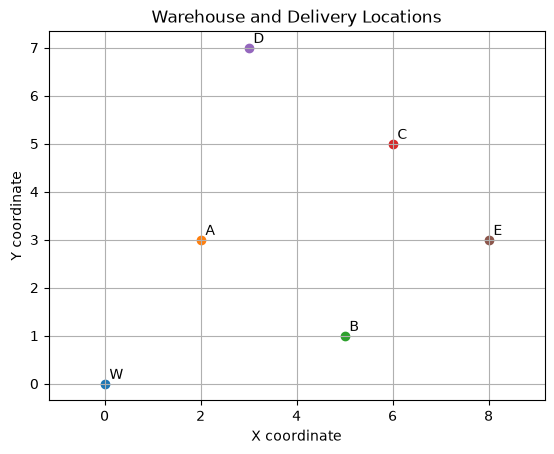

In [14]:

for name, coordinates in locations.items():
    x = coordinates[0]
    y = coordinates[1]

    plt.scatter(x, y)
    plt.text(x + 0.1, y + 0.1, name)

plt.title("Warehouse and Delivery Locations")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.axis("equal")
plt.show()



**Figure 1 — Warehouse and Delivery Locations**

This figure shows the warehouse (W) and five delivery locations (A, B, C, D, E) in a two-dimensional coordinate system.

Each point represents a location with fixed coordinates. The horizontal and vertical axes represent the x and y coordinates.

This visualization illustrates the spatial arrangement of the locations before calculating and comparing delivery routes.


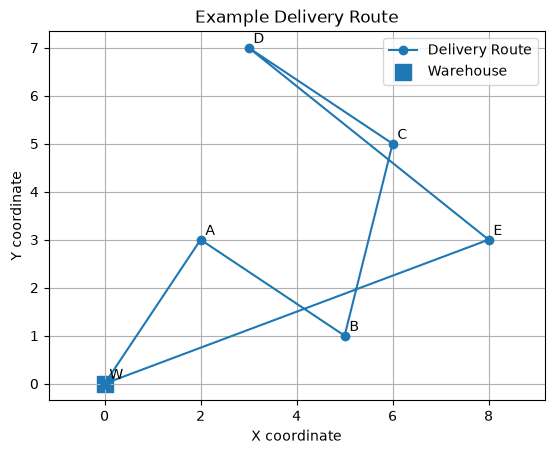

In [15]:
x_values = []
y_values = []

for point_name in route:
    coordinates = locations[point_name]
    x_values.append(coordinates[0])
    y_values.append(coordinates[1])

plt.plot(x_values, y_values, marker="o", label="Delivery Route")

warehouse_x = locations["W"][0]
warehouse_y = locations["W"][1]
plt.scatter(warehouse_x, warehouse_y, s=120, marker="s", label="Warehouse")

for name, coordinates in locations.items():
    x = coordinates[0]
    y = coordinates[1]
    plt.text(x + 0.1, y + 0.1, name)

plt.title("Example Delivery Route")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.savefig("../images/example_delivery_route.png", dpi=300, bbox_inches="tight")
plt.show()


**Figure 2 — Example Delivery Route**

This figure illustrates a valid delivery route connecting the warehouse (W) and the five delivery locations (A, B, C, D, E).

The courier starts at the warehouse, visits each delivery location exactly once, and returns to the warehouse following the sequence W → A → B → C → D → E → W.

The lines represent straight-line travel segments calculated using Euclidean distance. The total length of this route is approximately **29.89 distance units**.

Although the route satisfies all delivery conditions, it is not necessarily the optimal route. More efficient routes will be investigated and compared later in the project.



### 7. Permutations, Factorials and Mathematical Optimization

#### 7.1 Permutations

A permutation is an arrangement of elements in a specific order, without repetition.

In route optimization, the order of visiting delivery locations matters because different orders can produce different total route lengths.

For example, three delivery locations A, B and C can be visited in six different orders:

- A → B → C
- A → C → B
- B → A → C
- B → C → A
- C → A → B
- C → B → A

The warehouse (W) remains fixed as the starting and ending point.

#### 7.2 Factorials and Number of Possible Routes

The number of permutations of $n$ distinct elements is calculated using the factorial:

$$
n! = n \times (n-1) \times \cdots \times 2 \times 1
$$

For five delivery locations:

$$
5! = 5 \times 4 \times 3 \times 2 \times 1 = 120
$$

Therefore, our problem has **120 possible ordered delivery sequences**, with the warehouse fixed at the beginning and end of each route.

#### 7.3 Factorial Growth

The number of possible routes increases rapidly as the number of delivery locations grows.

| Delivery Locations | Number of Permutations |
|--------------------|------------------------|
| 3 | 6 |
| 4 | 24 |
| 5 | 120 |
| 6 | 720 |
| 7 | 5040 |

For example:

$$
6! = 6 \times 5! = 720
$$

$$
7! = 7 \times 6! = 5040
$$

This factorial growth makes checking every possible route increasingly expensive as the number of delivery locations increases.

#### 7.4 Route Reversal and Symmetry

Euclidean distance is symmetric:

$$
d(A,B) = d(B,A)
$$

Therefore, a route and its reverse have the same total length.

For example:

$$
W \rightarrow A \rightarrow B \rightarrow C \rightarrow W
$$

and

$$
W \rightarrow C \rightarrow B \rightarrow A \rightarrow W
$$

These are different ordered sequences, but their total distances are equal.

For five delivery locations, each of the 120 ordered routes has a corresponding reverse route with the same total distance.

If the direction of travel is ignored, the number of distinct tours up to reversal is:

$$
\frac{5!}{2} = \frac{120}{2} = 60
$$

However, this does not necessarily mean there are 60 different route lengths, because different tours may also have equal total distances.


In this project, we will keep all **120 permutations**, including reversed routes, to make the implementation simple and easy to understand.


#### 7.5 Mathematical Optimization

The objective of route optimization is to find the valid route with the minimum total distance.

Let $\pi$ represent a permutation of the five delivery locations, and let $L(\pi)$ represent the total length of the corresponding route.

The optimization problem is:

$$
\min_{\pi \in S_5} L(\pi)
$$

Here, $S_5$ is the set of all 120 permutations of the five delivery locations.

We distinguish between:

- **Valid Route:** A route that satisfies all delivery conditions.
- **Best Found Route:** The shortest route among those examined so far.
- **Globally Optimal Route:** A route with the minimum distance among all valid routes.

A Brute Force algorithm can find a globally optimal route by evaluating all 120 permutations and comparing their total distances.

In the following Python implementation, we will first calculate factorials and generate permutations. The route optimization algorithms will be implemented in later sections.


In [16]:

number_of_routes = math.factorial(5)

print("Number of possible routes:", number_of_routes)


Number of possible routes: 120


In [17]:

for n in range(3, 8):
    print(f"{n} delivery locations: {math.factorial(n)} permutations")

3 delivery locations: 6 permutations
4 delivery locations: 24 permutations
5 delivery locations: 120 permutations
6 delivery locations: 720 permutations
7 delivery locations: 5040 permutations


In [18]:

import itertools

In [19]:

delivery_points = ["A", "B", "C", "D", "E"]

all_permutations = list(itertools.permutations(delivery_points))

print("Total permutations:", len(all_permutations))
print("First permutation:", all_permutations[0])


Total permutations: 120
First permutation: ('A', 'B', 'C', 'D', 'E')


In [20]:

valid_permutations = True

for permutation in all_permutations:
    if len(permutation) != 5 or set(permutation) != set(delivery_points):
        valid_permutations = False
        break

print("All permutations are valid:", valid_permutations)
print("Warehouse included in permutations:", any("W" in p for p in all_permutations))


All permutations are valid: True
Warehouse included in permutations: False


In [21]:

for permutation in all_permutations[:5]:
    full_route = ["W"] + list(permutation) + ["W"]
    print(" -> ".join(full_route))


W -> A -> B -> C -> D -> E -> W
W -> A -> B -> C -> E -> D -> W
W -> A -> B -> D -> C -> E -> W
W -> A -> B -> D -> E -> C -> W
W -> A -> B -> E -> C -> D -> W



### 8. Random Route Algorithm

#### 8.1 Mathematical Idea

The Random Route algorithm generates a valid delivery route by randomly arranging the five delivery locations without repetition.

The warehouse (W) remains fixed as the starting and ending point, while only the delivery locations A, B, C, D, and E are randomly reordered.

With five delivery locations, the number of possible ordered routes is:

$$
5! = 5 \times 4 \times 3 \times 2 \times 1 = 120
$$

For example, one possible randomly generated route is:

$$
W \rightarrow A \rightarrow E \rightarrow C \rightarrow B \rightarrow D \rightarrow W
$$

A valid random route must start at the warehouse, visit each delivery location exactly once, and return to the warehouse.

The total route length is calculated using Euclidean distances between consecutive locations and the existing `calculate_route_length()` function.

Random Route does not consider distances when choosing the order of deliveries. Therefore, it does not guarantee the shortest possible route.

In this project, Random Route serves as a baseline for comparison with the Nearest Neighbor and Brute Force algorithms.



#### 8.2 Algorithm Steps

The Random Route algorithm follows these steps:

1. Start with the five delivery locations: A, B, C, D, and E.
2. Randomly rearrange the delivery locations without repetition.
3. Add the warehouse (W) at the beginning and end of the route.
4. Calculate the total route length using the existing `calculate_route_length()` function.
5. Display the generated route and its total distance.

The algorithm produces a valid delivery route, but it does not guarantee an optimal solution because the order of visits is selected randomly.



#### 8.3 Python Implementation


In [22]:

import random


In [23]:

random_delivery_points = random.sample(delivery_points, 5)

print("Random delivery order:", random_delivery_points)


Random delivery order: ['A', 'D', 'E', 'C', 'B']


In [24]:
random_route = ["W"] + random_delivery_points + ["W"]

print("Random full route:", random_route)

Random full route: ['W', 'A', 'D', 'E', 'C', 'B', 'W']


In [25]:

random_route_length = calculate_route_length(random_route, locations)

print("Random route length:", random_route_length)
print("Rounded route length:", round(random_route_length, 2))


Random route length: 26.182333402471137
Rounded route length: 26.18



#### 8.4 Results and Visualization

The Random Route algorithm generated a valid delivery route by randomly arranging the five delivery locations.

The generated route and its total distance are displayed in the Python output above.

The following visualization illustrates the order of the delivery locations and the straight-line connections between them.


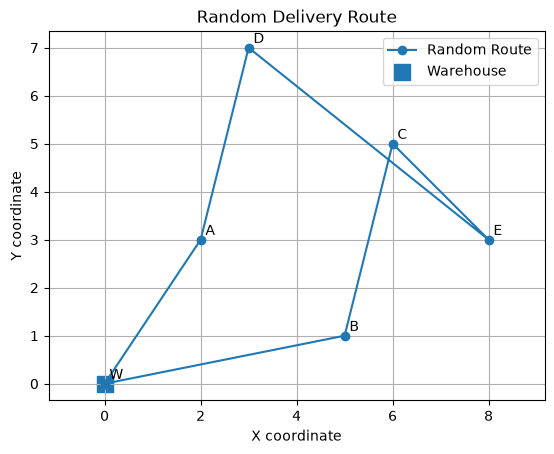

In [36]:

x_values = []
y_values = []

for point_name in random_route:
    coordinates = locations[point_name]
    x_values.append(coordinates[0])
    y_values.append(coordinates[1])

plt.plot(x_values, y_values, marker="o", label="Random Route")

warehouse_x = locations["W"][0]
warehouse_y = locations["W"][1]

plt.scatter(warehouse_x, warehouse_y, s=120, marker="s", label="Warehouse")

for name, coordinates in locations.items():
    x = coordinates[0]
    y = coordinates[1]
    plt.text(x + 0.1, y + 0.1, name)

plt.title("Random Delivery Route")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.savefig("../images/random_delivery_route.png", dpi=300, bbox_inches="tight")
plt.show()



**Figure 3 — Random Delivery Route**

This figure illustrates a randomly generated valid delivery route connecting the warehouse (W) and the five delivery locations (A, B, C, D, E).

The route starts and ends at the warehouse, visiting each delivery location exactly once. The lines represent straight-line travel segments based on Euclidean distance.

The visiting order is generated randomly, without considering the distances between locations. Therefore, the route is valid but is not guaranteed to be optimal.

The route serves as a baseline for comparison with the Nearest Neighbor and Brute Force algorithms.


#### 8.5 Limitations

The Random Route algorithm is a simple method for generating valid delivery routes, but it has several limitations.

- It does not consider the distances between delivery locations when selecting their visiting order.
- It does not guarantee finding the shortest possible route.
- Different executions may produce different routes and total distances.
- Although a randomly generated route may be optimal by chance, the algorithm cannot confirm that it is globally optimal.

Despite these limitations, Random Route provides a useful baseline for evaluating more systematic approaches.

In this project, its results will be compared with the Nearest Neighbor and Brute Force algorithms to examine how different route selection strategies affect the total travel distance.



### 9. Nearest Neighbor Algorithm

#### 9.1 Mathematical Idea

The Nearest Neighbor algorithm is a heuristic method for constructing a valid delivery route.

Unlike Random Route, which selects the visiting order randomly, Nearest Neighbor uses Euclidean distances to choose the next delivery location.

At each step, the algorithm selects the nearest unvisited delivery location from the current position.

The courier starts at the warehouse (W), visits each of the five delivery locations exactly once, and returns to the warehouse.

The mathematical selection rule is:

$$
P_{\text{next}} = \arg\min_{P \in U} d(P_{\text{current}}, P)
$$

where:

- $P_{\text{current}}$ is the current location.
- $U$ is the set of unvisited delivery locations.
- $d(P_{\text{current}}, P)$ is the Euclidean distance between the current location and an unvisited location.
- $\arg\min$ selects the location with the smallest distance.

Nearest Neighbor makes a locally optimal choice at each step, but these choices do not necessarily produce the globally shortest route.

Therefore, the algorithm does not guarantee a globally optimal solution.

In this project, Nearest Neighbor will be compared with Random Route and Brute Force to evaluate different approaches to finding efficient delivery routes.



#### 9.2 Algorithm Steps

The Nearest Neighbor algorithm follows these steps:

1. Start at the warehouse (W).
2. Create a list of all five unvisited delivery locations: A, B, C, D, and E.
3. Calculate the Euclidean distance from the current location to each unvisited delivery location.
4. Select the nearest unvisited location.
5. Add the selected location to the route and remove it from the list of unvisited locations.
6. Update the current location to the selected delivery location.
7. Repeat steps 3–6 until all five delivery locations have been visited.
8. Return to the warehouse (W).
9. Calculate the total route length using the existing `calculate_route_length()` function.

At each step, distances are calculated from the current location, not always from the warehouse.

The algorithm constructs a valid route by making the shortest available local choice at each step, without evaluating all possible routes.



#### 9.3 Python Implementation


In [27]:

unvisited = delivery_points.copy()
nearest_neighbor_route = ["W"]
current_location = "W"

print("Unvisited locations:", unvisited)
print("Starting route:", nearest_neighbor_route)
print("Current location:", current_location)


Unvisited locations: ['A', 'B', 'C', 'D', 'E']
Starting route: ['W']
Current location: W


In [28]:

for point in unvisited:
    distance = euclidean_distance(locations[current_location], locations[point])
    print(f"W -> {point}: {distance:.2f}")


W -> A: 3.61
W -> B: 5.10
W -> C: 7.81
W -> D: 7.62
W -> E: 8.54


In [29]:

nearest_point = min(
    unvisited,
    key=lambda point: euclidean_distance(
        locations[current_location],
        locations[point]
    )
)

print("Nearest unvisited location:", nearest_point)


Nearest unvisited location: A


In [30]:

nearest_neighbor_route.append(nearest_point)
unvisited.remove(nearest_point)
current_location = nearest_point

print("Updated route:", nearest_neighbor_route)
print("Remaining unvisited locations:", unvisited)
print("Current location:", current_location)


Updated route: ['W', 'A']
Remaining unvisited locations: ['B', 'C', 'D', 'E']
Current location: A


In [31]:

for point in unvisited:
    distance = euclidean_distance(locations[current_location], locations[point])
    print(f"{current_location} -> {point}: {distance:.2f}")


A -> B: 3.61
A -> C: 4.47
A -> D: 4.12
A -> E: 6.00


In [32]:

while unvisited:
    nearest_point = min(
        unvisited,
        key=lambda point: euclidean_distance(
            locations[current_location],
            locations[point]
        )
    )

    nearest_neighbor_route.append(nearest_point)
    unvisited.remove(nearest_point)
    current_location = nearest_point

    print("Current route:", " -> ".join(nearest_neighbor_route))


Current route: W -> A -> B
Current route: W -> A -> B -> E
Current route: W -> A -> B -> E -> C
Current route: W -> A -> B -> E -> C -> D


In [33]:

nearest_neighbor_route.append("W")

print("Complete Nearest Neighbor route:", " -> ".join(nearest_neighbor_route))
print("Remaining unvisited locations:", unvisited)


Complete Nearest Neighbor route: W -> A -> B -> E -> C -> D -> W
Remaining unvisited locations: []


In [34]:

nearest_neighbor_length = calculate_route_length(nearest_neighbor_route, locations)

print("Nearest Neighbor route length:", nearest_neighbor_length)
print("Rounded route length:", round(nearest_neighbor_length, 2))


Nearest Neighbor route length: 24.866405332466055
Rounded route length: 24.87



#### 9.4 Results and Visualization

The Nearest Neighbor algorithm constructs a valid delivery route by selecting the nearest unvisited location at each step.

For the given warehouse and delivery coordinates, the algorithm produces the following route:

**W → A → B → E → C → D → W**

The total route length is approximately **24.87 distance units**, calculated using the existing `calculate_route_length()` function.

The following visualization illustrates the order of visits and the straight-line connections between locations.

Although Nearest Neighbor makes the shortest available local choice at each step, the resulting route is not guaranteed to be globally optimal.

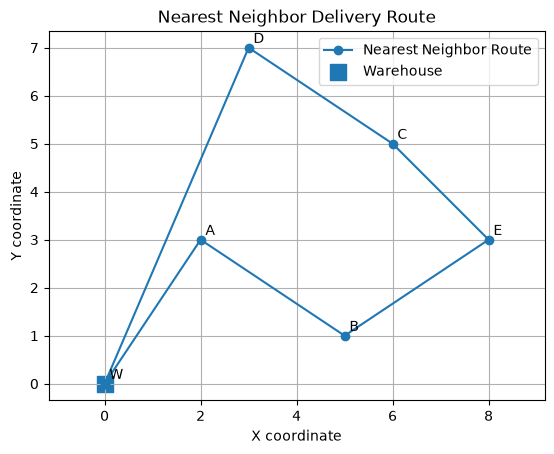

In [35]:

x_values = []
y_values = []

for point_name in nearest_neighbor_route:
    coordinates = locations[point_name]
    x_values.append(coordinates[0])
    y_values.append(coordinates[1])

plt.plot(x_values, y_values, marker="o", label="Nearest Neighbor Route")

warehouse_x = locations["W"][0]
warehouse_y = locations["W"][1]
plt.scatter(warehouse_x, warehouse_y, s=120, marker="s", label="Warehouse")

for name, coordinates in locations.items():
    x = coordinates[0]
    y = coordinates[1]
    plt.text(x + 0.1, y + 0.1, name)

plt.title("Nearest Neighbor Delivery Route")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.savefig("../images/nearest_neighbor_route.png", dpi=300, bbox_inches="tight")
plt.show()



**Figure 4 — Nearest Neighbor Delivery Route**

This figure illustrates the delivery route constructed using the Nearest Neighbor algorithm.

Starting from the warehouse (W), the algorithm repeatedly selects the nearest unvisited delivery location based on Euclidean distance.

The resulting route is **W → A → B → E → C → D → W**, with a total length of approximately **24.87 distance units**.

The warehouse is represented by a square marker, while the delivery locations are connected by straight-line segments.

Although the algorithm makes the shortest available local choice at each step, the resulting route is not necessarily globally optimal. This will be evaluated later using the Brute Force algorithm.



#### 9.5 Limitations

The Nearest Neighbor algorithm is a simple and efficient heuristic for constructing valid delivery routes, but it has several limitations.

- It makes decisions based only on the distance to the nearest unvisited location.
- It does not consider how each local choice affects the total route length.
- It does not evaluate all possible delivery sequences.
- It does not guarantee finding the globally shortest route.
- The resulting route may depend on the selected starting point and the arrangement of delivery locations.

Despite these limitations, Nearest Neighbor provides a useful approach for finding a valid route without examining every possible permutation.

In this project, its result will be compared with Random Route and Brute Force to evaluate the effectiveness of different route optimization strategies.



### References

The mathematical concepts and Python implementations in this project are based on the following educational materials and technical documentation.

**SoftUni Course Materials**

1. SoftUni. *Math Concepts for Developers — High-School Maths*. Course lecture materials and material summary.

2. SoftUni. *Math Concepts for Developers — Linear Algebra*. Course lecture materials and material summary.

3. SoftUni. *Math Concepts for Developers — Probability and Combinatorics*. Course lecture materials and summary.

**Python Documentation**

4. Python Software Foundation. *Python Standard Library — math*. https://docs.python.org/3/library/math.html

5. Python Software Foundation. *Python Standard Library — itertools*. https://docs.python.org/3/library/itertools.html

These sources support the mathematical explanations, factorial calculations, and permutation generation used in the project.
